<a href="https://colab.research.google.com/github/2075anant/AI-in-Cyber-Security-Lab-Assignment-3/blob/main/AI_in_Cyber_Security_Lab_Assignment_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

np.random.seed(42)
tf.random.set_seed(42)

try:
    from google.colab import files
    uploaded = files.upload()
    csv_file = next(iter(uploaded))
except ImportError:
    csv_file = "simple_cyber_activity.csv"

df = pd.read_csv(csv_file)
print("Dataset shape:", df.shape)
display(df.head())




Saving simple_login_activity.csv to simple_login_activity.csv
Dataset shape: (101, 6)


,record_id,failed_logins,login_hour,new_device,download_mb,label
0,1,4.0,1,0,164.9,Suspicious
1,2,3.0,3,1,250.6,Suspicious
2,3,3.0,10,0,145.1,Normal
3,4,2.0,11,0,397.8,Normal
4,5,1.0,3,0,409.3,Normal


In [6]:
import pandas as pd

# Inspect dataset structure
print("Dataset information:")
df.info()

print("\nMissing values by column:")
display(df.isnull().sum().to_frame("missing_values"))

# Map 'download_mb' to 'data_transfer_mb' if it exists to align with our expected features
if "download_mb" in df.columns and "data_transfer_mb" not in df.columns:
    df = df.rename(columns={"download_mb": "data_transfer_mb"})

# Encode target labels to binary values (0 = Normal, 1 = Attack/Suspicious)
if df["label"].dtype == "object":
    # Map 'Normal' to 0 and 'Suspicious'/'Attack' to 1
    df["label"] = df["label"].apply(lambda x: 0 if str(x).strip().lower() == 'normal' else 1)

print("\nClass counts (0 = Normal, 1 = Attack/Suspicious):")
display(df["label"].value_counts().sort_index().to_frame("count"))

# The lab dataset features
features = [
    "failed_logins",
    "login_hour",
    "new_device",
    "data_transfer_mb"
]
required_columns = features + ["label"]
missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {missing_columns}")

# Remove rows with missing values in the selected inputs/target, if any.
df = df.dropna(subset=required_columns).copy()

X = df[features]
y = df["label"].astype(int)

print("\nRows used:", len(df))
print("Feature columns:", features)
print("Target values:", sorted(y.unique()))

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101 entries, 0 to 100
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   record_id      101 non-null    int64  
 1   failed_logins  100 non-null    float64
 2   login_hour     101 non-null    int64  
 3   new_device     101 non-null    int64  
 4   download_mb    100 non-null    float64
 5   label          101 non-null    object 
dtypes: float64(2), int64(3), object(1)
memory usage: 4.9+ KB

Missing values by column:


,missing_values
record_id,0
failed_logins,1
login_hour,0
new_device,0
download_mb,1
label,0



Class counts (0 = Normal, 1 = Attack/Suspicious):


,count
label,
0,75
1,26



Rows used: 99
Feature columns: ['failed_logins', 'login_hour', 'new_device', 'data_transfer_mb']
Target values: [np.int64(0), np.int64(1)]


In [7]:
# 75% training / 25% testing split, stratified, random_state=42
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# Fit scaler only on training data; reuse it for test/new records.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)
print("Training class counts:")
display(y_train.value_counts().sort_index().rename(index={0: "Normal", 1: "Attack"}).to_frame("count"))

print("\nNormalization explanation:")
print("StandardScaler transforms features to a comparable scale using the training-set mean and standard deviation.")


Training shape: (74, 4)
Testing shape: (25, 4)
Training class counts:


,count
label,
Normal,55
Attack,19



Normalization explanation:
StandardScaler transforms features to a comparable scale using the training-set mean and standard deviation.


In [8]:
# Build the 4-8-4-1 dense neural network
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(4,)),
    tf.keras.layers.Dense(8, activation="relu"),
    tf.keras.layers.Dense(4, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 81 (324.00 B)

 Trainable params: 81 (324.00 B)

 Non-trainable params: 0 (0.00 B)

In [9]:
# Train for 20 epochs
history = model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.20,
    epochs=20,
    batch_size=8,
    verbose=1
)

print(f"Final training accuracy: {history.history['accuracy'][-1] * 100:.2f}%")
print(f"Final validation accuracy: {history.history['val_accuracy'][-1] * 100:.2f}%")
print("An epoch is one complete pass through the training data.")
print("A batch is a subset of training examples processed before the model updates its weights.")

Epoch 1/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 79ms/step - accuracy: 0.4915 - loss: 0.6827 - val_accuracy: 0.3333 - val_loss: 0.8073
Epoch 2/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.5254 - loss: 0.6747 - val_accuracy: 0.3333 - val_loss: 0.7949
Epoch 3/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.5593 - loss: 0.6676 - val_accuracy: 0.4000 - val_loss: 0.7829
Epoch 4/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.5593 - loss: 0.6607 - val_accuracy: 0.4000 - val_loss: 0.7711
Epoch 5/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.6102 - loss: 0.6535 - val_accuracy: 0.4667 - val_loss: 0.7594
Epoch 6/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.6610 - loss: 0.6462 - val_accuracy: 0.5333 - val_loss: 0.7478
Epoch 7/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.6949 - loss: 0.6388 - val_accuracy: 0.5333 - val_loss: 0.7365
Epoch 8/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.6949 - loss: 0.6312 - val_accuracy: 0.5333 - val_loss: 0.7255


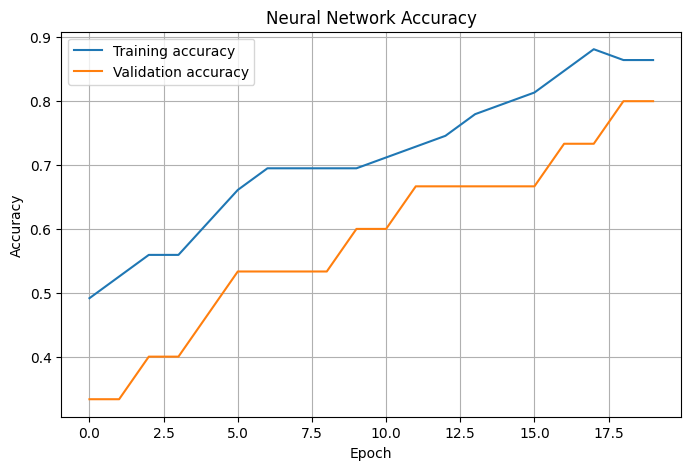

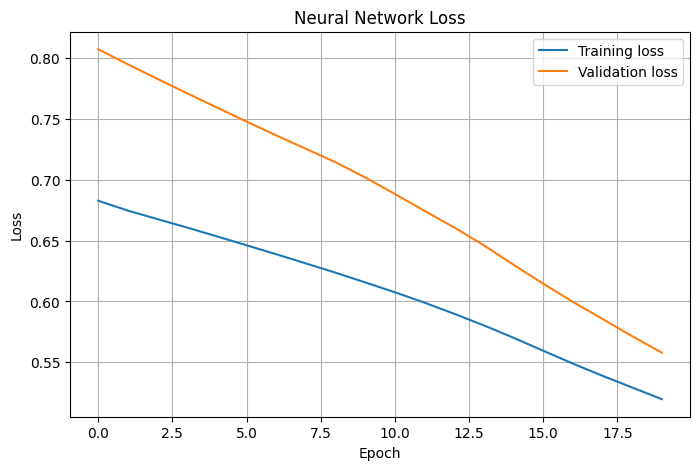

Test accuracy: 84.00%
Test loss: 0.5093


In [10]:
# Plot training and validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.title("Neural Network Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Plot training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("Neural Network Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

# Evaluate on held-out test data
test_loss, test_accuracy = model.evaluate(X_test_scaled, y_test, verbose=0)
print(f"Test accuracy: {test_accuracy * 100:.2f}%")
print(f"Test loss: {test_loss:.4f}")


In [12]:
# Test-set predictions and confusion matrix
test_probabilities = model.predict(X_test_scaled, verbose=0).flatten()
test_predictions = (test_probabilities >= 0.50).astype(int)

print("Confusion matrix (rows = actual, columns = predicted; 0 = Normal, 1 = Attack):")
print(confusion_matrix(y_test, test_predictions))
print("\nClassification report:")
print(classification_report(y_test, test_predictions, target_names=["Normal", "Attack"], zero_division=0))

Confusion matrix (rows = actual, columns = predicted; 0 = Normal, 1 = Attack):
[[18  1]
 [ 3  3]]

Classification report:
              precision    recall  f1-score   support

      Normal       0.86      0.95      0.90        19
      Attack       0.75      0.50      0.60         6

    accuracy                           0.84        25
   macro avg       0.80      0.72      0.75        25
weighted avg       0.83      0.84      0.83        25



In [13]:
# Three new cyber-activity records from the lab manual
new_records = pd.DataFrame([
    {"failed_logins": 0, "login_hour": 11, "new_device": 0, "data_transfer_mb": 35},
    {"failed_logins": 7, "login_hour": 1, "new_device": 1, "data_transfer_mb": 250},
    {"failed_logins": 2, "login_hour": 23, "new_device": 1, "data_transfer_mb": 850}
])

# Neural-network predictions
new_scaled = scaler.transform(new_records[features])
probabilities = model.predict(new_scaled, verbose=0).flatten()

results = new_records.copy()
results["nn_probability"] = probabilities.round(3)
results["nn_prediction"] = np.where(probabilities >= 0.50, "Attack", "Normal")

# Decision Tree trained on the same training split
tree = DecisionTreeClassifier(max_depth=4, random_state=42)
tree.fit(X_train, y_train)

tree_test_predictions = tree.predict(X_test)
tree_accuracy = accuracy_score(y_test, tree_test_predictions)

results["tree_prediction"] = np.where(
    tree.predict(new_records[features]) == 1,
    "Attack",
    "Normal"
)

print(f"Neural-network test accuracy: {test_accuracy * 100:.2f}%")
print(f"Decision-tree test accuracy: {tree_accuracy * 100:.2f}%")
display(results)

Neural-network test accuracy: 84.00%
Decision-tree test accuracy: 92.00%


,failed_logins,login_hour,new_device,data_transfer_mb,nn_probability,nn_prediction,tree_prediction
0,0,11,0,35,0.269,Normal,Normal
1,7,1,1,250,0.900,Attack,Attack
2,2,23,1,850,0.442,Normal,Attack
